# Portfolio Optimisation Using Frank Wolfe Variants


## Brief description of what we want to do

- We have n available assets.
- We call xi the quantity of money invested on the i-th asset during the
considered period and with ri the returns on the i-th asset.
- We have two different constraints:
    - Non-negativity for the variables (i.e., xi ≥ 0). Meaning that short selling (selling asset that we still don’t own) is not allowed.
    - Budget constraint: $\sum_{i = 1}^{n} = B$, the total amount of money invested needs to be equal to the budget B (B can be simply set to 1).

- $r \in \mathbb{R}^n $ is a randomly generated vector with mean $\hat{r}$ and covariance $\sum$

- Expected return will be $\hat{r}^Tx$ and variance $x^T\sum x$
- Classic portfolio problem, described by Markowits (1952), is a convex quadratic
programming problem:
$$
\begin{aligned}
\min_{x \in \mathbb{R}^n} \quad & \gamma x^\top \Sigma x - \bar{r}^\top x \\
\text{s.t.} \quad & e^\top x = 1 \\
& x \ge 0
\end{aligned}
$$
- with $\gamma > 0$ risk-aversion parameter.
- GOAL: Finding the set of assets that minimises the variance (risk connected to the given portfolio) while maximising the expected return (we obviously need to satisfy budget and non-negativity constraints).

## Import Libraries and Data

In [ ]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import importlib
import Oracle 
importlib.reload(Oracle)
from Oracle import PortfolioOptimisation_rolling, PortfolioOptimisation_Whole_Dataset
import time
from scipy.stats import skew, kurtosis

dataset_paths = {
    'DowJones': 'DowJones.xlsx',
    'FTSE100': 'FTSE100.xlsx',
    'S&P 500': 'SP500.xlsx'
}
datasets = {}

for name, path in dataset_paths.items():

    data = pd.read_excel(path, sheet_name='Assets_Returns', header=None)
    datasets[name] = data
    print(f"\nDataset: {name}")
    print(f"Number of assets: {data.shape[1]}")
    print(f"Number of time periods: {data.shape[0]}")
    print(f"Number of Missing values: {data.isna().sum().sum()}")




Dataset: DowJones
Number of assets: 28
Number of time periods: 1363
Number of Missing values: 0

Dataset: FTSE100
Number of assets: 83
Number of time periods: 717
Number of Missing values: 0

Dataset: S&P 500
Number of assets: 442
Number of time periods: 595
Number of Missing values: 0


## Initial EDA

### Asset Return Statistics

In [110]:
asset_return_stats = []

for name, data in datasets.items():

    average_returns = data.mean(axis=0, skipna=True)


    asset_return_stats.append({
        'Dataset': name,
        'Number of Assets': len(average_returns),
        'Mean Average Return': average_returns.mean(),
        'Median Average Return': average_returns.median(),
        'Std Average Return': average_returns.std(ddof=1),
        'Minimum Average Return': average_returns.min(),
        'Maximum Average Return': average_returns.max(),
        'Skewness': skew(average_returns),
        'Kurtosis': kurtosis(average_returns)
    })


asset_return_stats_df = pd.DataFrame(asset_return_stats)

print(asset_return_stats_df.to_string(index=False))

 Dataset  Number of Assets  Mean Average Return  Median Average Return  Std Average Return  Minimum Average Return  Maximum Average Return  Skewness  Kurtosis
DowJones                28             0.002885               0.002506            0.001258                0.001278                0.006054  1.288624  0.671913
 FTSE100                83             0.002508               0.002507            0.001506               -0.000610                0.008018  0.807218  1.337827
 S&P 500               442             0.002546               0.002339            0.001471               -0.000626                0.010325  1.499171  4.517561


### Dataset Summary

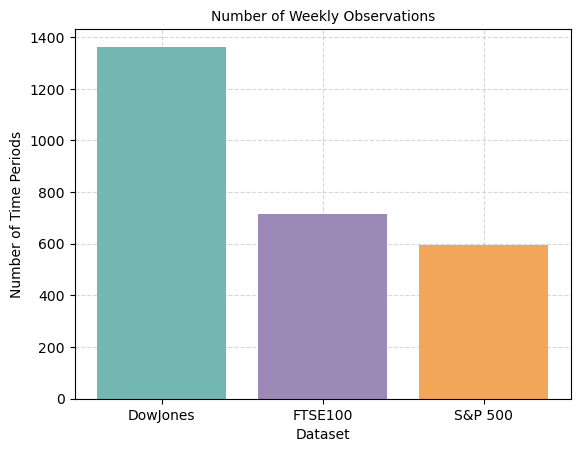

In [111]:
summary = []
for name, data in datasets.items():
    values = data.to_numpy().flatten()
    summary.append({
        "Dataset": name,
        "Number of Assets": data.shape[1],
        "Number of Time Periods": data.shape[0],
        "Total Observations": data.size,
        "Mean Return": np.mean(values),
        "Median Return": np.median(values),
        "Std Return": np.std(values, ddof=1),
        "Minimum Return": np.min(values),
        "Maximum Return": np.max(values),
        "Skewness": skew(values),
        "Kurtosis": kurtosis(values)
    })


summary_df = pd.DataFrame(summary)

x = summary_df["Dataset"]
y = summary_df["Number of Time Periods"]



plt.title( "Number of Weekly Observations", fontsize = 10)

plt.xlabel("Dataset")
plt.ylabel("Number of Time Periods")
bars = plt.bar(x, y, color=["#72B7B2", "#9C89B8", "#F2A65A"],zorder=2)

plt.grid(axis="both", linestyle="--", alpha=0.5, zorder=1)



### Correlation

In [112]:
correlation_results = []

for name, data in datasets.items():
    corr = data.corr()  
    upper_values = corr.values[np.triu_indices_from(corr.values, k=1)]
    upper_values = upper_values[np.isfinite(upper_values)]    
    correlation_results.append({
        "Dataset": name,
        "Mean Correlation": np.mean(upper_values),
        "Median Correlation": np.median(upper_values),
        "Minimum Correlation": np.min(upper_values),
        "Maximum Correlation": np.max(upper_values)
    })

correlation_df = pd.DataFrame(correlation_results)

print(correlation_df.to_string(index=False))


 Dataset  Mean Correlation  Median Correlation  Minimum Correlation  Maximum Correlation
DowJones          0.336582            0.325762             0.100503             0.787045
 FTSE100          0.345084            0.338179            -0.089827             0.845918
 S&P 500          0.412351            0.406816            -0.008174             0.984175


## Initial Results Per Algorithm

In [113]:
all_results = {}
summary_list = []

for name, path in dataset_paths.items():
    data = pd.read_excel(path, sheet_name='Assets_Returns', header=None)
    r_bar = data.mean().values
    Sigma = data.cov().values
    print(f"Dataset: {name}")
    print(f"Number of assets: {data.shape[1]}")
    print(f"Number of time periods: {data.shape[0]}")
    
    model = PortfolioOptimisation_Whole_Dataset(Sigma=Sigma, r_bar=r_bar, gamma =1)

    results = model.run_all_fw(max_iter=10000, tol=1e-6)
    all_results[name] = results

    for variant, result in results.items():
        history = result['hist']
        summary_list.append({
            'Dataset': name,
            'Algorithm': variant,
            'Num Assets (n)': data.shape[1],
            'Time Periods (T)': data.shape[0],
            'Iterations': len(history),
            'Final obj': history['obj'].iloc[-1],
            'Final Duality Gap': history['gap'].iloc[-1],
            'Active Size (final)': history['active'].iloc[-1],
            'Time (s)': result['time']
        })

    
summary_df = pd.DataFrame(summary_list)
print("\n" + summary_df.to_string(index=False))

Dataset: DowJones
Number of assets: 28
Number of time periods: 1363
Dataset: FTSE100
Number of assets: 83
Number of time periods: 717
Dataset: S&P 500
Number of assets: 442
Number of time periods: 595

 Dataset Algorithm  Num Assets (n)  Time Periods (T)  Iterations  Final obj  Final Duality Gap  Active Size (final)  Time (s)
DowJones        fw              28              1363          29  -0.004183       9.447384e-07                    4  0.000997
DowJones      asfw              28              1363           9  -0.004183       6.307742e-08                    4  0.000000
DowJones      pwfw              28              1363          13  -0.004183       3.594216e-07                    4  0.000000
 FTSE100        fw              83               717        4172  -0.005239       9.939590e-07                    5  0.190999
 FTSE100      asfw              83               717          11  -0.005240       3.355678e-07                    4  0.000000
 FTSE100      pwfw              83        

## Active set analysis

In [114]:
for name, path in dataset_paths.items():
    data = pd.read_excel(path, sheet_name='Assets_Returns', header=None)
    r_bar = data.mean().values
    Sigma = data.cov().values
    model = PortfolioOptimisation_Whole_Dataset(Sigma=Sigma, r_bar=r_bar, gamma=1)
    results = model.run_all_fw(max_iter=1000, tol=1e-6)
    asset_names = list(data.columns)
    print(f"Dataset: {name}")
    for variant, result in results.items():
        x_final = result['x']
        active = np.where(np.abs(x_final) > 1e-6)[0]
        print(f"\n{variant}")
        print(f"Number of active assets: {len(active)}")
        for i in active:
            print(f"  {asset_names[i]}: {x_final[i]:.3f}")

Dataset: DowJones

fw
Number of active assets: 4
  0: 0.176
  17: 0.310
  18: 0.452
  21: 0.061

asfw
Number of active assets: 4
  0: 0.176
  17: 0.310
  18: 0.452
  21: 0.062

pwfw
Number of active assets: 4
  0: 0.176
  17: 0.310
  18: 0.452
  21: 0.061
Dataset: FTSE100

fw
Number of active assets: 5
  0: 0.001
  63: 0.069
  65: 0.351
  77: 0.297
  82: 0.283

asfw
Number of active assets: 4
  63: 0.069
  65: 0.351
  77: 0.297
  82: 0.283

pwfw
Number of active assets: 4
  63: 0.069
  65: 0.351
  77: 0.297
  82: 0.283
Dataset: S&P 500

fw
Number of active assets: 6
  0: 0.006
  61: 0.181
  86: 0.224
  95: 0.149
  147: 0.312
  171: 0.128

asfw
Number of active assets: 5
  61: 0.183
  86: 0.225
  95: 0.150
  147: 0.313
  171: 0.129

pwfw
Number of active assets: 5
  61: 0.183
  86: 0.225
  95: 0.150
  147: 0.313
  171: 0.129


## Last 595 time periods

In [115]:
res_equal_595 = {}
equal_period_summary_list = []

for name, path in dataset_paths.items():
    data = pd.read_excel(path, sheet_name='Assets_Returns', header=None)

    data = data.tail(595).reset_index(drop=True)

    r_bar = data.mean().values
    Sigma = data.cov().values

    print(f"Dataset: {name}")
    print(f"Number of assets: {data.shape[1]}")
    print(f"Number of time periods: {data.shape[0]}")

    model = PortfolioOptimisation_Whole_Dataset(
        Sigma=Sigma,
        r_bar=r_bar,
        gamma=1
    )

    results = model.run_all_fw(max_iter=10000, tol=1e-6)
    res_equal_595[name] = results

    for variant, result in results.items():
        history = result['hist']

        equal_period_summary_list.append({
            'Dataset': name,
            'Algorithm': variant,
            'Num Assets (n)': data.shape[1],
            'Time Periods (T)': data.shape[0],
            'Iterations': len(history),
            'Final Objective': history['obj'].iloc[-1],
            'Final Duality Gap': history['gap'].iloc[-1],
            'Active Size (final)': history['active'].iloc[-1],
            'Time (s)': result['time']
        })

equal_period_summary_list = pd.DataFrame(equal_period_summary_list)

print("\n" + equal_period_summary_list.to_string(index=False))

Dataset: DowJones
Number of assets: 28
Number of time periods: 595
Dataset: FTSE100
Number of assets: 83
Number of time periods: 595
Dataset: S&P 500
Number of assets: 442
Number of time periods: 595

 Dataset Algorithm  Num Assets (n)  Time Periods (T)  Iterations  Final Objective  Final Duality Gap  Active Size (final)  Time (s)
DowJones        fw              28               595           2        -0.004419      -6.776264e-20                    2  0.000000
DowJones      asfw              28               595           2        -0.004419      -6.776264e-20                    2  0.000000
DowJones      pwfw              28               595           2        -0.004419      -6.776264e-20                    2  0.000000
 FTSE100        fw              83               595        2698        -0.004434       9.788012e-07                    9  0.139178
 FTSE100      asfw              83               595          20        -0.004434       7.426999e-07                    8  0.001021
 FTSE10

In [116]:
for name, path in dataset_paths.items():
    data = pd.read_excel(path, sheet_name='Assets_Returns', header=None)
    data = data.tail(595).reset_index(drop=True)
    r_bar = data.mean().values
    Sigma = data.cov().values
    model = PortfolioOptimisation_Whole_Dataset(Sigma=Sigma, r_bar=r_bar, gamma=1)
    results = model.run_all_fw(max_iter=1000, tol=1e-6)
    asset_names = list(data.columns)
    print(f"Dataset: {name}")
    for variant, result in results.items():
        x_final = result['x']
        active = np.where(np.abs(x_final) > 1e-6)[0]
        print(f"\n{variant}")
        print(f"Number of active assets: {len(active)}")
        for i in active:
            print(f"  {asset_names[i]}: {x_final[i]:.3f}")

Dataset: DowJones

fw
Number of active assets: 2
  0: 0.945
  21: 0.055

asfw
Number of active assets: 2
  0: 0.945
  21: 0.055

pwfw
Number of active assets: 2
  0: 0.945
  21: 0.055
Dataset: FTSE100

fw
Number of active assets: 9
  0: 0.000
  21: 0.068
  31: 0.039
  37: 0.004
  39: 0.056
  49: 0.071
  65: 0.259
  77: 0.238
  82: 0.264

asfw
Number of active assets: 8
  21: 0.069
  31: 0.039
  37: 0.004
  39: 0.056
  49: 0.070
  65: 0.259
  77: 0.239
  82: 0.264

pwfw
Number of active assets: 8
  21: 0.069
  31: 0.039
  37: 0.004
  39: 0.057
  49: 0.071
  65: 0.259
  77: 0.238
  82: 0.264
Dataset: S&P 500

fw
Number of active assets: 6
  0: 0.006
  61: 0.181
  86: 0.224
  95: 0.149
  147: 0.312
  171: 0.128

asfw
Number of active assets: 5
  61: 0.183
  86: 0.225
  95: 0.150
  147: 0.313
  171: 0.129

pwfw
Number of active assets: 5
  61: 0.183
  86: 0.225
  95: 0.150
  147: 0.313
  171: 0.129


## Results Graphics 

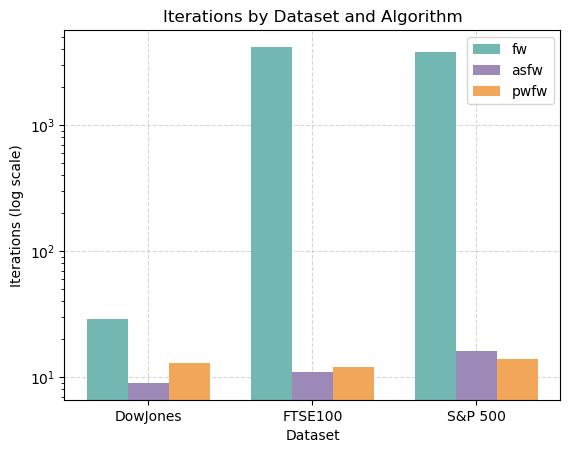

In [117]:
methods = ["fw", "asfw", "pwfw"]
datasets = summary_df["Dataset"].unique()

x = np.arange(len(datasets))
width = 0.25

colours = ["#72B7B2", "#9C89B8", "#F2A65A"]

for i, m in enumerate(methods):
    subset = summary_df[summary_df["Algorithm"] == m].set_index("Dataset")
    values = subset.reindex(datasets)["Iterations"]

    plt.bar(x + (i - 1) * width, values, width, label=m, color=colours[i], zorder=2)

plt.yscale("log")

plt.xlabel("Dataset")
plt.ylabel("Iterations (log scale)")
plt.title("Iterations by Dataset and Algorithm")
plt.xticks(x, datasets)

plt.legend()
plt.grid(axis="both", linestyle="--", alpha=0.5, zorder=1)


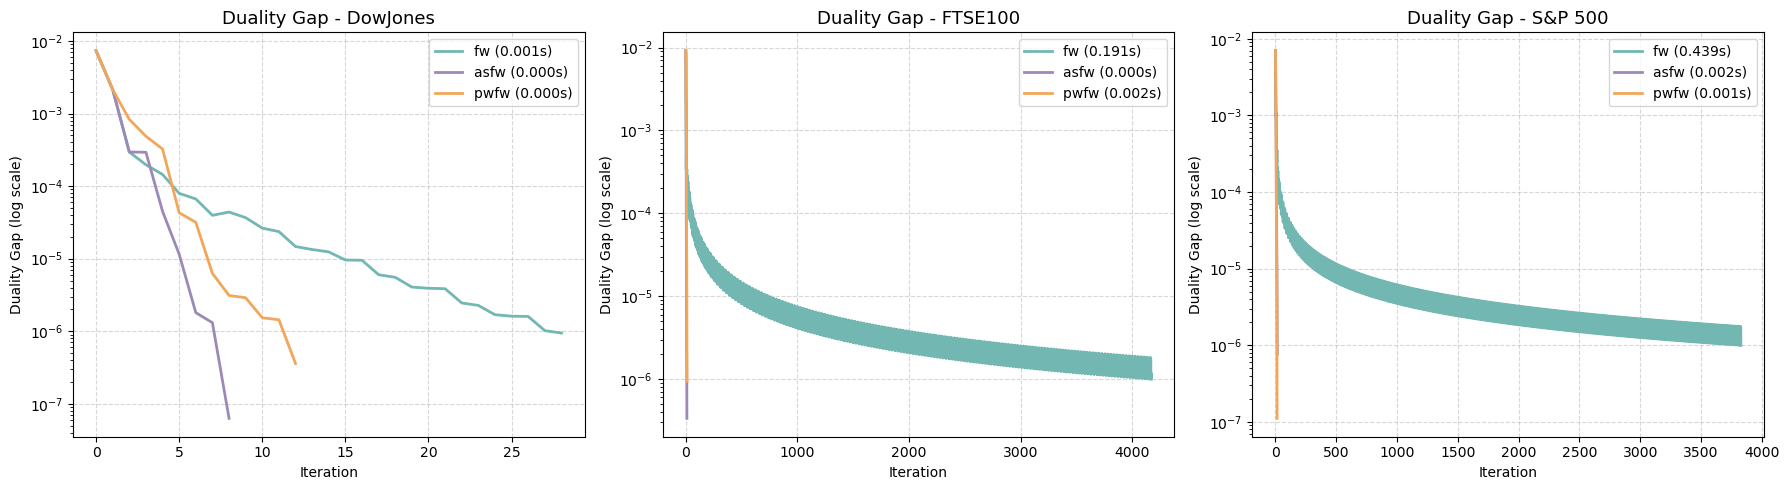

In [118]:
colours = ["#72B7B2", "#9C89B8", "#F2A65A"]

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

for idx, (name, results) in enumerate(all_results.items()):

    ax = axes[idx]

    for i, (variant, result) in enumerate(results.items()):

        history = result["hist"]

        ax.semilogy(
            history["iter"],
            history["gap"],
            label=f"{variant} ({result['time']:.3f}s)",
            linewidth=2,
            color=colours[i],
            zorder=2
        )

    ax.set_title(f"Duality Gap - {name}", fontsize=13)
    ax.set_xlabel("Iteration")
    ax.set_ylabel("Duality Gap (log scale)")
    ax.legend()
    ax.grid(axis="both", linestyle="--", alpha=0.5, zorder=1)

plt.tight_layout()
plt.show()

## Diminishing grad Method vs Exact Line Search

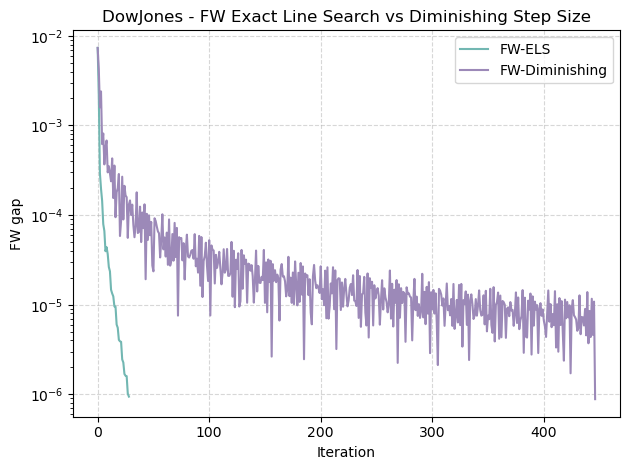

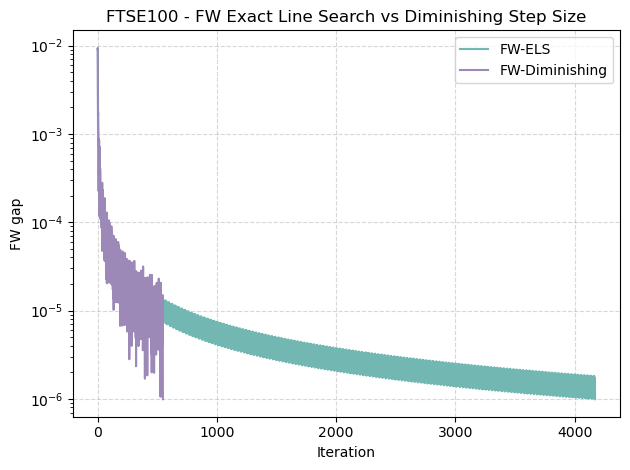

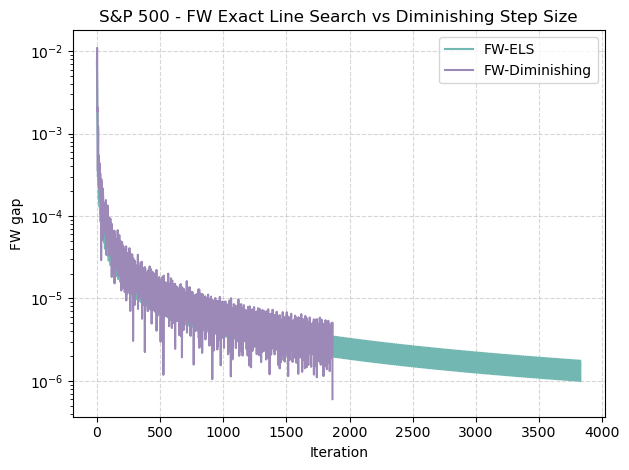


 Dataset         Method  Active assets     Time  Iterations  Final objective    Final gap
DowJones         FW-ELS              4 0.003524          29        -0.004183 9.447384e-07
DowJones FW-Diminishing              4 0.016676         447        -0.004183 8.847010e-07
 FTSE100         FW-ELS              5 0.202103        4172        -0.005239 9.939590e-07
 FTSE100 FW-Diminishing              4 0.012801         548        -0.005240 9.939650e-07
 S&P 500         FW-ELS              6 0.355168        3829        -0.007494 9.986227e-07
 S&P 500 FW-Diminishing              5 0.104207        1866        -0.007494 6.005146e-07


In [119]:
fw_comparison = []

colours = ["#72B7B2", "#9C89B8"]

for name, path in dataset_paths.items():

    data = pd.read_excel(path, sheet_name="Assets_Returns", header=None)
    r_bar = data.mean().values
    Sigma = data.cov().values

    model = PortfolioOptimisation_Whole_Dataset(Sigma=Sigma, r_bar=r_bar, gamma=1)

    x_fw_exact, hist_fw_exact, time_fw_exact = model.fw(
        max_iter=10000,
        use_line_search=True
    )

    x_fw_dim, hist_fw_dim, time_fw_dim = model.fw(
        max_iter=10000,
        use_line_search=False
    )

    plt.semilogy(
        hist_fw_exact["iter"],
        hist_fw_exact["gap"],
        label="FW-ELS",
        color=colours[0],
        zorder=2
    )

    plt.semilogy(
        hist_fw_dim["iter"],
        hist_fw_dim["gap"],
        label="FW-Diminishing",
        color=colours[1],
        zorder=2
    )

    plt.xlabel("Iteration")
    plt.ylabel("FW gap")
    plt.title(f"{name} - FW Exact Line Search vs Diminishing Step Size")
    plt.legend()
    plt.grid(axis="both", linestyle="--", alpha=0.5, zorder=1)

    plt.tight_layout()
    plt.show()

    fw_comparison.append({
        "Dataset": name,
        "Method": "FW-ELS",
        "Active assets": np.sum(x_fw_exact > 1e-6),
        "Time": time_fw_exact,
        "Iterations": len(hist_fw_exact),
        "Final objective": hist_fw_exact["obj"].iloc[-1],
        "Final gap": hist_fw_exact["gap"].iloc[-1]
    })

    fw_comparison.append({
        "Dataset": name,
        "Method": "FW-Diminishing",
        "Active assets": np.sum(x_fw_dim > 1e-6),
        "Time": time_fw_dim,
        "Iterations": len(hist_fw_dim),
        "Final objective": hist_fw_dim["obj"].iloc[-1],
        "Final gap": hist_fw_dim["gap"].iloc[-1]
    })

fw_comparison_df = pd.DataFrame(fw_comparison)

print("\n" + fw_comparison_df.to_string(index=False))

## FW-LMO vs PGD-PROJECTION

In [120]:
operation_times = []
for name, path in dataset_paths.items():
    data = pd.read_excel(
        path,
        sheet_name="Assets_Returns",
        header=None
    )
    r_bar = data.mean().values
    Sigma = data.cov().values

    model = PortfolioOptimisation_Whole_Dataset(
        Sigma=Sigma,
        r_bar=r_bar,
        gamma=1
    )

    x = np.ones(model.n) / model.n
    grad = model.grad(x)
    y = x - 0.1 * grad
    repetitions = 10000

    start = time.time()
    for _ in range(repetitions):
        s_idx = np.argmin(grad)
    lmo_time = (time.time() - start) / repetitions


    start = time.time()
    for _ in range(repetitions):
        projected = model.project_simplex(y)
    projection_time = (time.time() - start) / repetitions

    operation_times.append({
        "Dataset": name,
        "Num Assets": model.n,
        "LMO Time": lmo_time,
        "Projection Time": projection_time,
        "Projection / LMO": projection_time / lmo_time
    })

operation_times_df = pd.DataFrame(operation_times)
print("\n" + operation_times_df.to_string(index=False))


 Dataset  Num Assets  LMO Time  Projection Time  Projection / LMO
DowJones          28  0.000003         0.000016          5.139510
 FTSE100          83  0.000002         0.000017          7.853067
 S&P 500         442  0.000003         0.000029          9.329928


## Projected grad Descent Results

In [121]:
pgd_results = {}
summary_pgd = []

for name, path in dataset_paths.items():

    data = pd.read_excel(path, sheet_name="Assets_Returns", header=None)
    r_bar = data.mean().values
    Sigma = data.cov().values

    print(f"Dataset: {name}")
    print(f"Number of assets: {data.shape[1]}")
    print(f"Number of time periods: {data.shape[0]}")

    model = PortfolioOptimisation_Whole_Dataset(Sigma=Sigma, r_bar=r_bar, gamma=1
    )

    x, history, runtime = model.projected_grad(max_iter=10000, tol=1e-6)

    pgd_results[name] = {
        "x": x,
        "hist": history,
        "time": runtime
    }

    summary_pgd.append({
        "Dataset": name,
        "Algorithm": "PGD",
        "Num Assets (n)": data.shape[1],
        "Time Periods (T)": data.shape[0],
        "Iterations": len(history),
        "Final Objective": history["obj"].iloc[-1],
        "Final Duality Gap": history["gap"].iloc[-1],
        "Active Size (final)": history["active"].iloc[-1],
        "Time (s)": runtime
    })

summary_pgd_df = pd.DataFrame(summary_pgd)
print("\n" + summary_pgd_df.to_string(index=False))

Dataset: DowJones
Number of assets: 28
Number of time periods: 1363
Dataset: FTSE100
Number of assets: 83
Number of time periods: 717
Dataset: S&P 500
Number of assets: 442
Number of time periods: 595

 Dataset Algorithm  Num Assets (n)  Time Periods (T)  Iterations  Final Objective  Final Duality Gap  Active Size (final)  Time (s)
DowJones       PGD              28              1363         102        -0.004183       7.774564e-09                    4  0.012408
 FTSE100       PGD              83               717         310        -0.005240       8.853915e-08                    4  0.016181
 S&P 500       PGD             442               595        1007        -0.007494       5.053631e-07                    5  0.150455


# Rolling-Window Portfolio Optimisation

## Risk Parameter Analysis

In [122]:
gammas = [0.01, 0.1, 0.5, 1, 5, 10]
methods = ("fw", "asfw", "pwfw")
initial_budget = 1
all_results = {}
for name, path in dataset_paths.items():

    data = pd.read_excel(
        path,
        sheet_name='Assets_Returns',
        header=None
    )

    print(f"\nDataset: {name}")
    print(f"Number of assets: {data.shape[1]}")
    print(f"Number of time periods: {data.shape[0]}")

    dataset_results = {}

    for gamma in gammas:

        print(f"Running gamma = {gamma}")

        model = PortfolioOptimisation_rolling(
            data=data,
            wind_size=52,
            gamma=gamma
        )

        results = model.rolling_backtest(
            max_iter=10000,
            tol=1e-6,
            f_horizon=4,
            methods=methods
        )

        dataset_results[gamma] = results

    all_results[name] = dataset_results


Dataset: DowJones
Number of assets: 28
Number of time periods: 1363
Running gamma = 0.01
Running gamma = 0.1
Running gamma = 0.5
Running gamma = 1
Running gamma = 5
Running gamma = 10

Dataset: FTSE100
Number of assets: 83
Number of time periods: 717
Running gamma = 0.01
Running gamma = 0.1
Running gamma = 0.5
Running gamma = 1
Running gamma = 5
Running gamma = 10

Dataset: S&P 500
Number of assets: 442
Number of time periods: 595
Running gamma = 0.01
Running gamma = 0.1
Running gamma = 0.5
Running gamma = 1
Running gamma = 5
Running gamma = 10


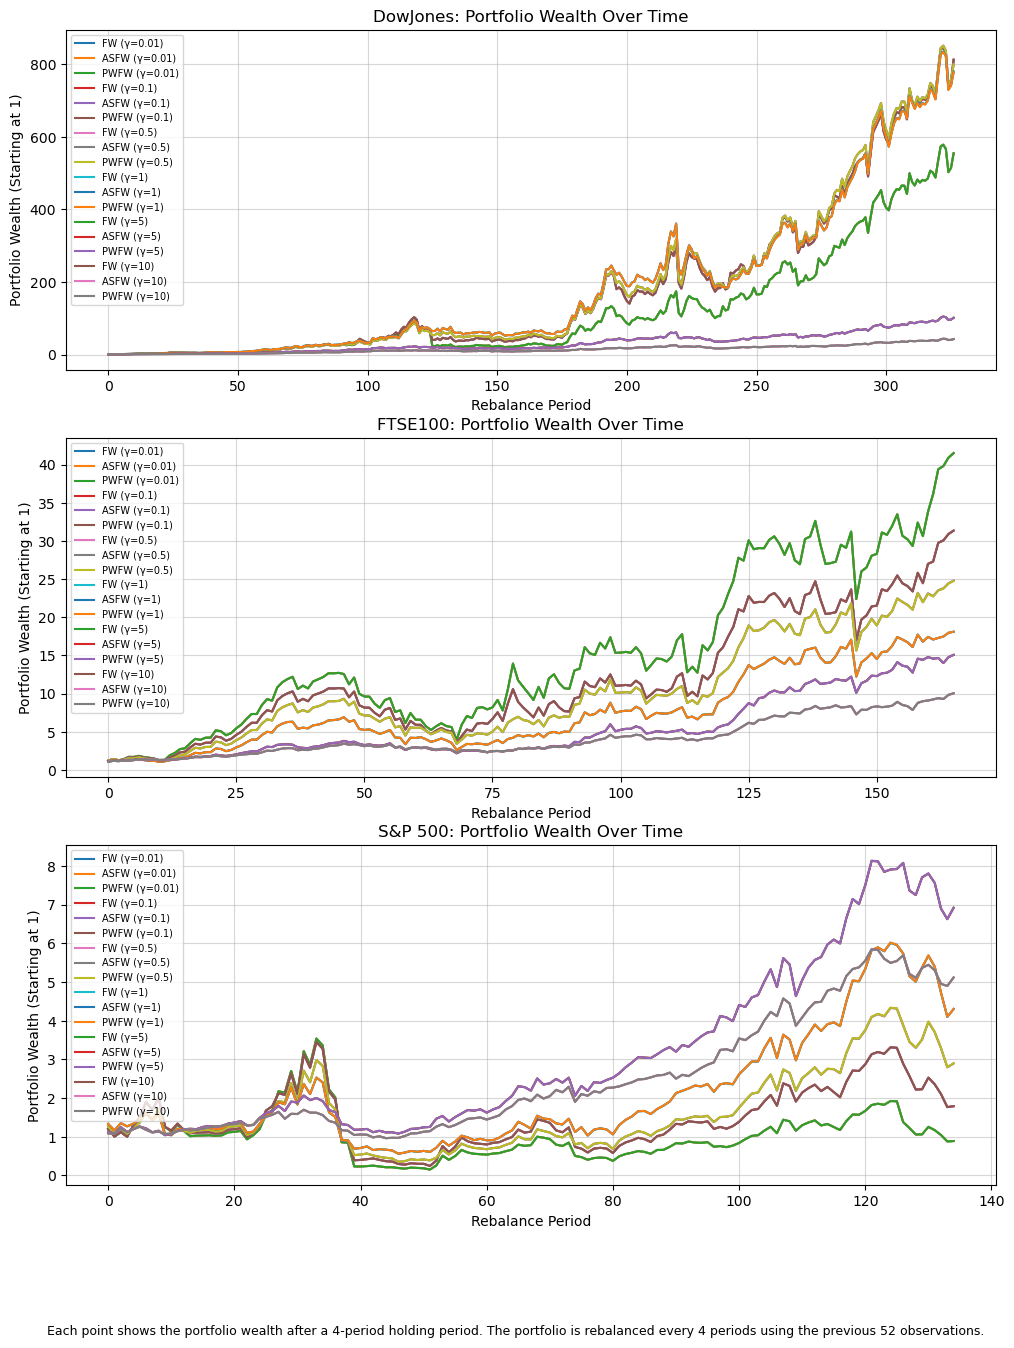

In [123]:
fig, axes = plt.subplots(3, 1, figsize=(12, 15))
for ax, (dataset_name, dataset_results) in zip(axes, all_results.items()):
    for gamma in gammas:
        df = dataset_results[gamma]
        for method in methods:
            method_df = df[
                df["method"] == method
            ].copy()
            method_df = method_df[
                method_df["f_horizon"] == 4
            ]
            method_df = method_df.sort_values(
                "rebalance_period"
            )
            ax.plot(
                method_df["rebalance_period"],
                method_df["budget"],
                label=f"{method.upper()} (γ={gamma})"
            )
    ax.set_title(f"{dataset_name}: Portfolio Wealth Over Time")
    ax.set_xlabel("Rebalance Period")
    ax.set_ylabel("Portfolio Wealth (Starting at 1)")
    ax.grid(True, alpha=0.5)
    ax.legend(fontsize=7, loc="upper left")

fig.text(
    0.5,
    0.01,
    "Each point shows the portfolio wealth after a 4-period holding period. "
    "The portfolio is rebalanced every 4 periods using the previous 52 observations.",
    ha="center",
    fontsize=9
)

plt.show()

In [124]:

summary = []
for dataset, results in all_results.items():
    for gamma in gammas:
        df = results[gamma]
        for method in methods:
            method_df = df[
                (df["method"] == method) &
                (df["f_horizon"] == 4)
            ].sort_values("rebalance_period")
            if method_df.empty:
                continue
            final = method_df["budget"].iloc[-1]
            summary.append([
                dataset,
                gamma,
                method,
                final
            ])
summary_df = pd.DataFrame(
    summary,
    columns=["Dataset", "Gamma", "Method", "Final Budget"]
)
best_overall = (summary_df.loc[
        summary_df.groupby("Dataset")["Final Budget"].idxmax()
    ]
    .sort_values("Dataset")
    .reset_index(drop=True)
)

print("\nBest Overall Result per Dataset:")
print(best_overall)


Best Overall Result per Dataset:
    Dataset  Gamma Method  Final Budget
0  DowJones   0.10   pwfw    812.104080
1   FTSE100   0.01     fw     41.500140
2   S&P 500   5.00   pwfw      6.921917


In [125]:
selected_gammas = {
    'DowJones': 0.10,
    'FTSE100': 0.01,
    'S&P 500': 5.00
}

methods = ("fw", "asfw", "pwfw")

summary = []

for name, path in dataset_paths.items():

    data = pd.read_excel(
        path,
        sheet_name='Assets_Returns',
        header=None
    )

    model = PortfolioOptimisation_rolling(
        data=data,
        wind_size=52,
        gamma=selected_gammas[name]
    )

    backtest = model.rolling_backtest(
        max_iter=10000,
        tol=1e-6,
        f_horizon=4,
        methods=methods
    )

    for method in methods:

        df = backtest[backtest['method'] == method]

        summary.append({
            'Dataset': name,
            'Gamma': selected_gammas[name],
            'Algorithm': method,
            'Iterations': df['iter'].mean(),
            'Runtime (s)': df['time'].mean(),
            'Objective': df['obj'].mean(),
            'Final Gap': df['gap'].mean(),
            'Active Assets': df['active'].mean()
        })

summary_df = pd.DataFrame(summary)

print(summary_df.to_string(index=False))

 Dataset  Gamma Algorithm  Iterations  Runtime (s)  Objective     Final Gap  Active Assets
DowJones   0.10        fw    1.807339     0.000220  -0.013262  2.036629e-09       1.076453
DowJones   0.10      asfw    1.785933     0.000282  -0.013262  8.990114e-10       1.076453
DowJones   0.10      pwfw    1.801223     0.000235  -0.013262  2.396063e-09       1.076453
 FTSE100   0.01        fw    2.024096     0.000252  -0.018063 -1.215380e-20       1.024096
 FTSE100   0.01      asfw    2.024096     0.000283  -0.018063 -1.215380e-20       1.024096
 FTSE100   0.01      pwfw    2.024096     0.000381  -0.018063 -1.215380e-20       1.024096
 S&P 500   5.00        fw 8910.451852     1.631343  -0.011766  2.608750e-06       9.155556
 S&P 500   5.00      asfw   47.200000     0.007951  -0.011767  7.521743e-07       7.955556
 S&P 500   5.00      pwfw   35.059259     0.005172  -0.011767  7.279190e-07       7.962963


## Only for PWFW

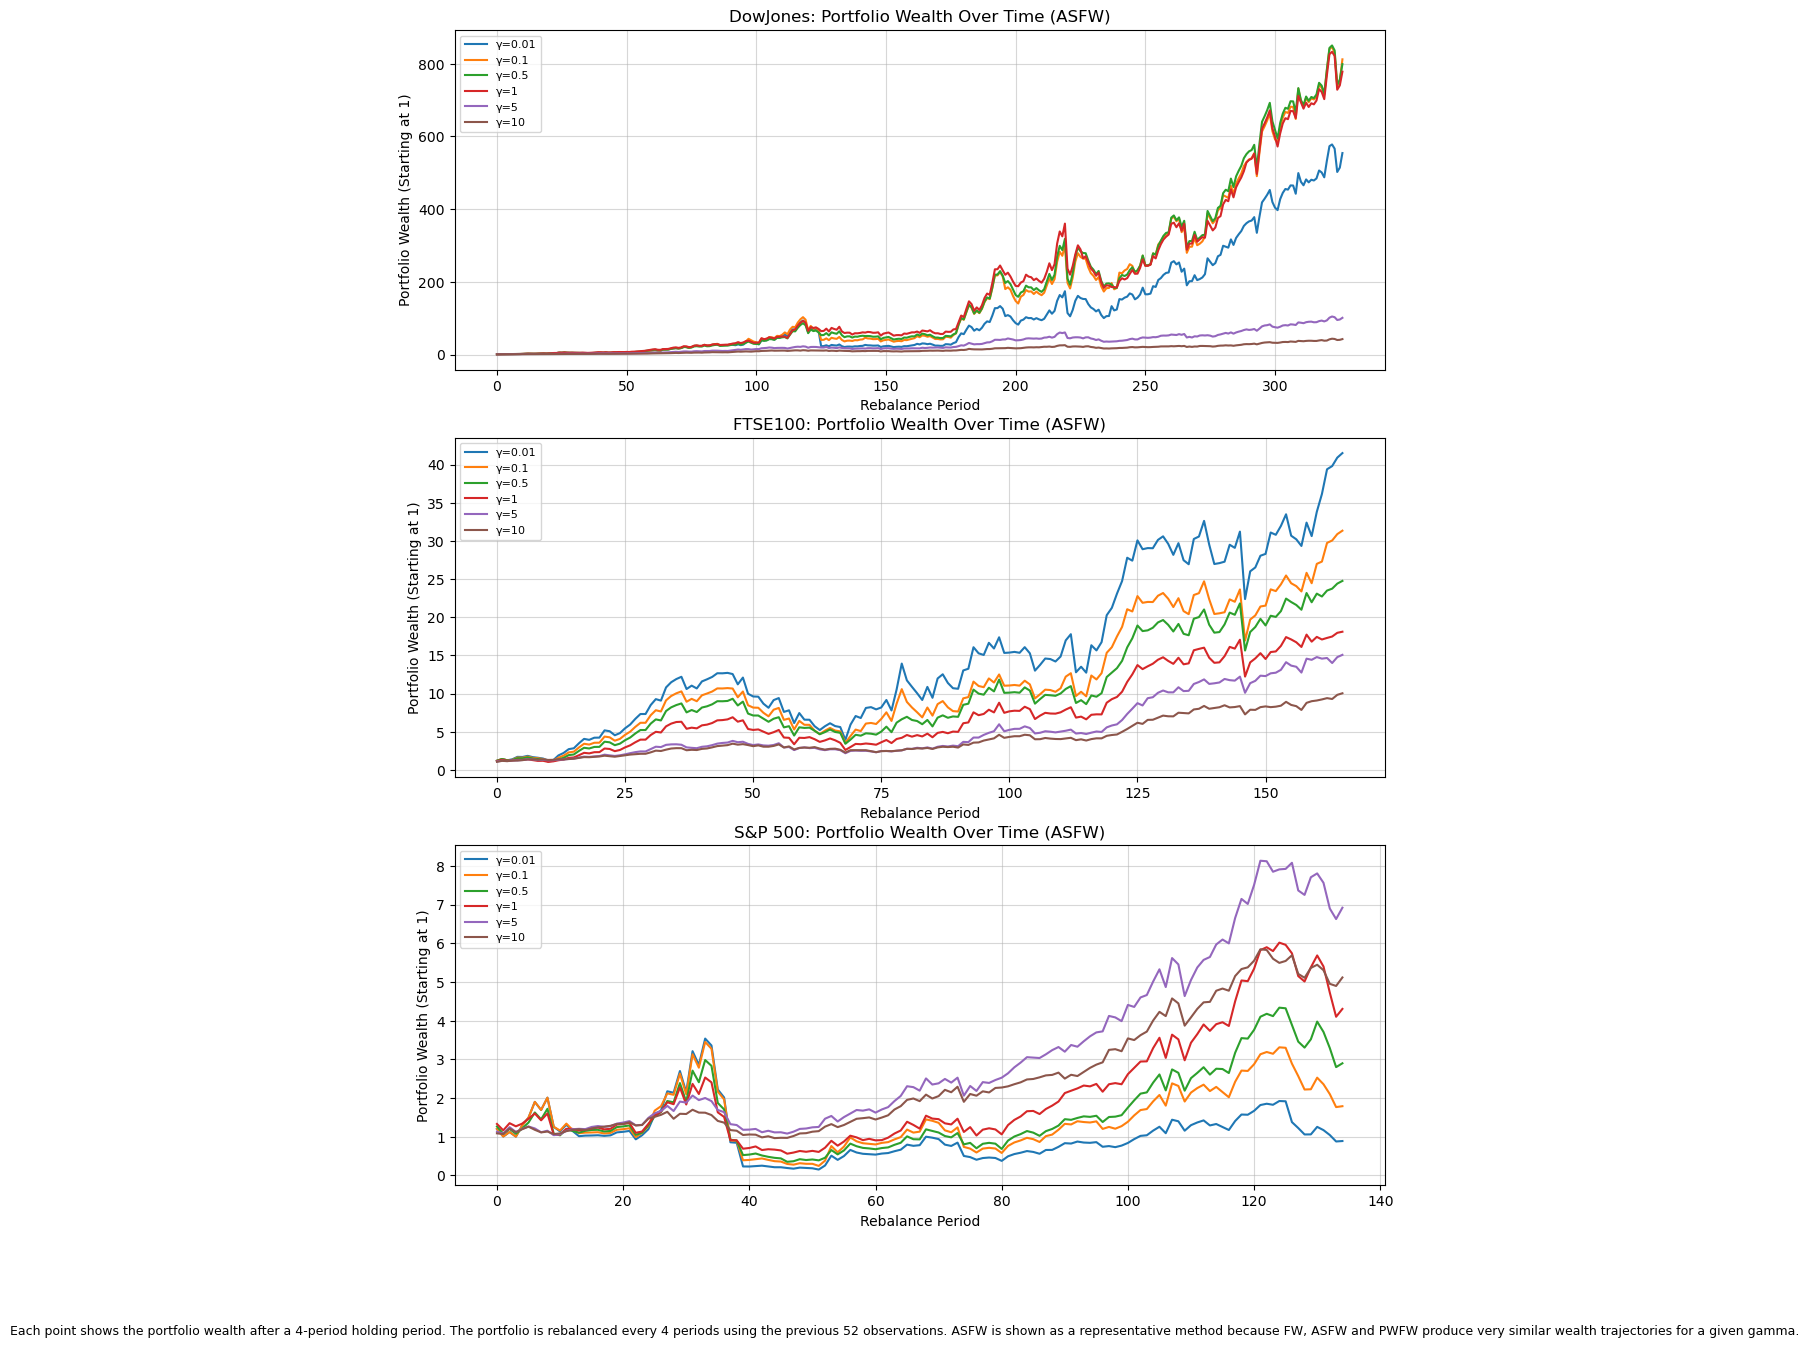

In [126]:
fig, axes = plt.subplots(3, 1, figsize=(12, 15))
plot_method = "pwfw"

for ax, (dataset_name, dataset_results) in zip(axes, all_results.items()):
    for gamma in gammas:
        df = dataset_results[gamma]
        method_df = df[
            (df["method"] == plot_method) &
            (df["f_horizon"] == 4)
        ].copy()

        method_df = method_df.sort_values("rebalance_period")

        ax.plot(
            method_df["rebalance_period"],
            method_df["budget"],
            label=f"γ={gamma}"
        )

    ax.set_title(f"{dataset_name}: Portfolio Wealth Over Time (ASFW)")
    ax.set_xlabel("Rebalance Period")
    ax.set_ylabel("Portfolio Wealth (Starting at 1)")
    ax.grid(True, alpha=0.5)
    ax.legend(fontsize=8, loc="upper left")

fig.text(
    0.5,
    0.01,
    "Each point shows the portfolio wealth after a 4-period holding period. "
    "The portfolio is rebalanced every 4 periods using the previous 52 observations. "
    "ASFW is shown as a representative method because FW, ASFW and PWFW produce "
    "very similar wealth trajectories for a given gamma.",
    ha="center",
    fontsize=9
)

plt.show()


## Last 595 Time Periods

In [127]:
gammas = [0.01, 0.1, 0.5, 1, 5, 10]
methods = ("fw", "asfw", "pwfw")
initial_budget = 1
all_results = {}

for name, path in dataset_paths.items():

    data = pd.read_excel(
        path,
        sheet_name="Assets_Returns",
        header=None
    )

    data = data.tail(595).reset_index(drop=True)

    print(f"\nDataset: {name}")
    print(f"Number of assets: {data.shape[1]}")
    print(f"Number of time periods: {data.shape[0]}")

    dataset_results = {}

    for gamma in gammas:

        print(f"Running gamma = {gamma}")

        model = PortfolioOptimisation_rolling(
            data=data,
            wind_size=52,
            gamma=gamma
        )

        results = model.rolling_backtest(
            max_iter=10000,
            tol=1e-6,
            f_horizon=4,
            methods=methods
        )

        dataset_results[gamma] = results

    all_results[name] = dataset_results


Dataset: DowJones
Number of assets: 28
Number of time periods: 595
Running gamma = 0.01
Running gamma = 0.1
Running gamma = 0.5
Running gamma = 1
Running gamma = 5
Running gamma = 10

Dataset: FTSE100
Number of assets: 83
Number of time periods: 595
Running gamma = 0.01
Running gamma = 0.1
Running gamma = 0.5
Running gamma = 1
Running gamma = 5
Running gamma = 10

Dataset: S&P 500
Number of assets: 442
Number of time periods: 595
Running gamma = 0.01
Running gamma = 0.1
Running gamma = 0.5
Running gamma = 1
Running gamma = 5
Running gamma = 10


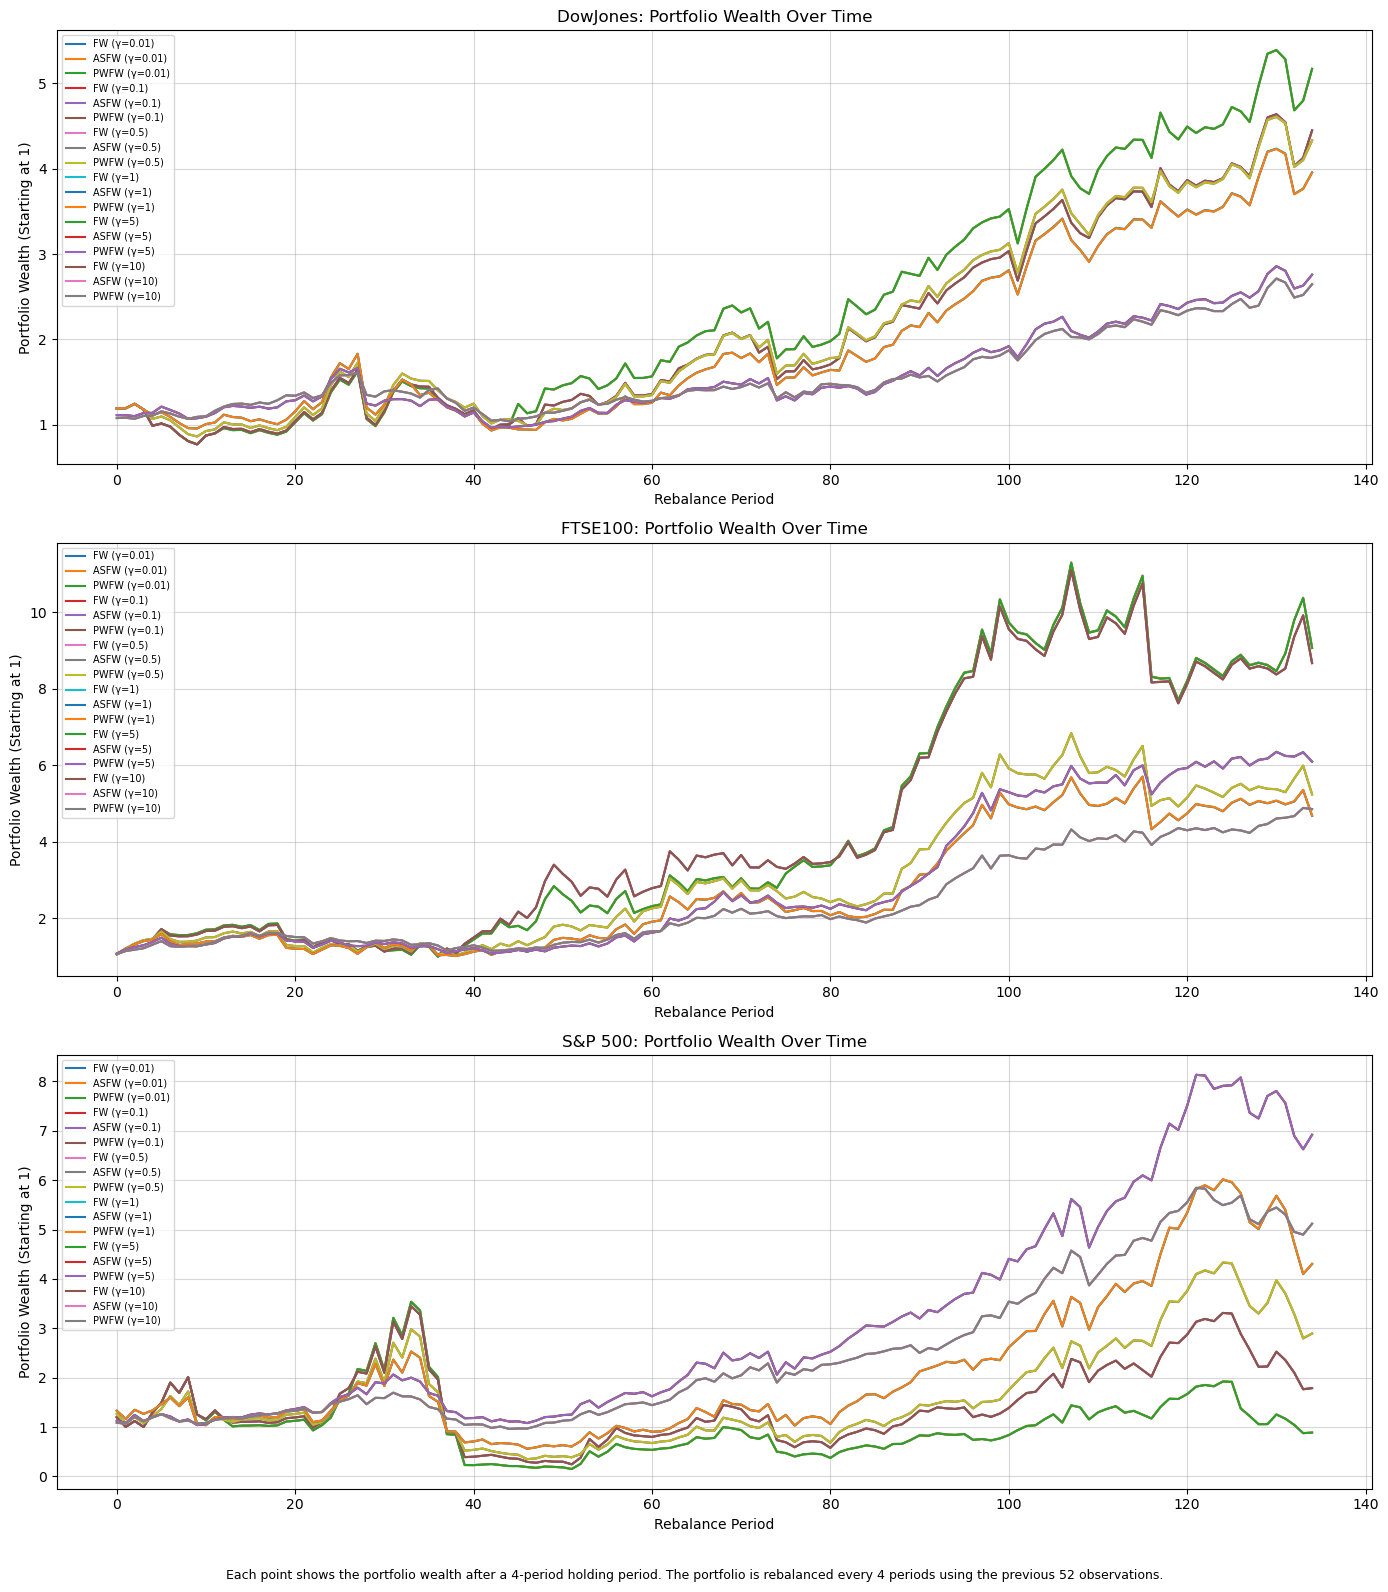

In [128]:

methods = ("fw", "asfw", "pwfw")
gammas = [0.01, 0.1, 0.5, 1, 5, 10]

fig, axes = plt.subplots(
    3, 1,
    figsize=(14, 16)
)

for ax, (dataset_name, dataset_results) in zip(axes, all_results.items()):
    for gamma in gammas:
        df = dataset_results[gamma].copy()
        for method in methods:
            method_df = df[
                (df["method"] == method) &
                (df["f_horizon"] == 4)
            ].copy()

            method_df = method_df.sort_values("rebalance_period")

            ax.plot(
                method_df["rebalance_period"],
                method_df["budget"],
                label=f"{method.upper()} (γ={gamma})"
            )

    ax.set_title(
        f"{dataset_name}: Portfolio Wealth Over Time"
    )
    ax.set_xlabel("Rebalance Period")
    ax.set_ylabel("Portfolio Wealth (Starting at 1)")
    ax.grid(True, alpha=0.5)
    ax.legend(fontsize=7, loc="upper left")

fig.text(
    0.5,
    0.01,
    "Each point shows the portfolio wealth after a 4-period holding period. "
    "The portfolio is rebalanced every 4 periods using the previous 52 observations.",
    ha="center",
    fontsize=9
)

plt.tight_layout(rect=[0, 0.03, 1, 1])
plt.show()





In [129]:

summary = []
for dataset, results in all_results.items():
    for gamma in gammas:
        df = results[gamma]
        for method in methods:
            method_df = df[
                (df["method"] == method) &
                (df["f_horizon"] == 4)
            ].sort_values("rebalance_period")
            if method_df.empty:
                continue
            final = method_df["budget"].iloc[-1]
            summary.append([
                dataset,
                gamma,
                method,
                final
            ])
summary_df = pd.DataFrame(
    summary,
    columns=["Dataset", "Gamma", "Method", "Final Budget"]
)
best_overall = (summary_df.loc[
        summary_df.groupby("Dataset")["Final Budget"].idxmax()
    ]
    .sort_values("Dataset")
    .reset_index(drop=True)
)

print("\nBest Overall Result per Dataset:")
print(best_overall)


Best Overall Result per Dataset:
    Dataset  Gamma Method  Final Budget
0  DowJones   0.01     fw      5.170787
1   FTSE100   0.01     fw      9.083370
2   S&P 500   5.00   pwfw      6.921917


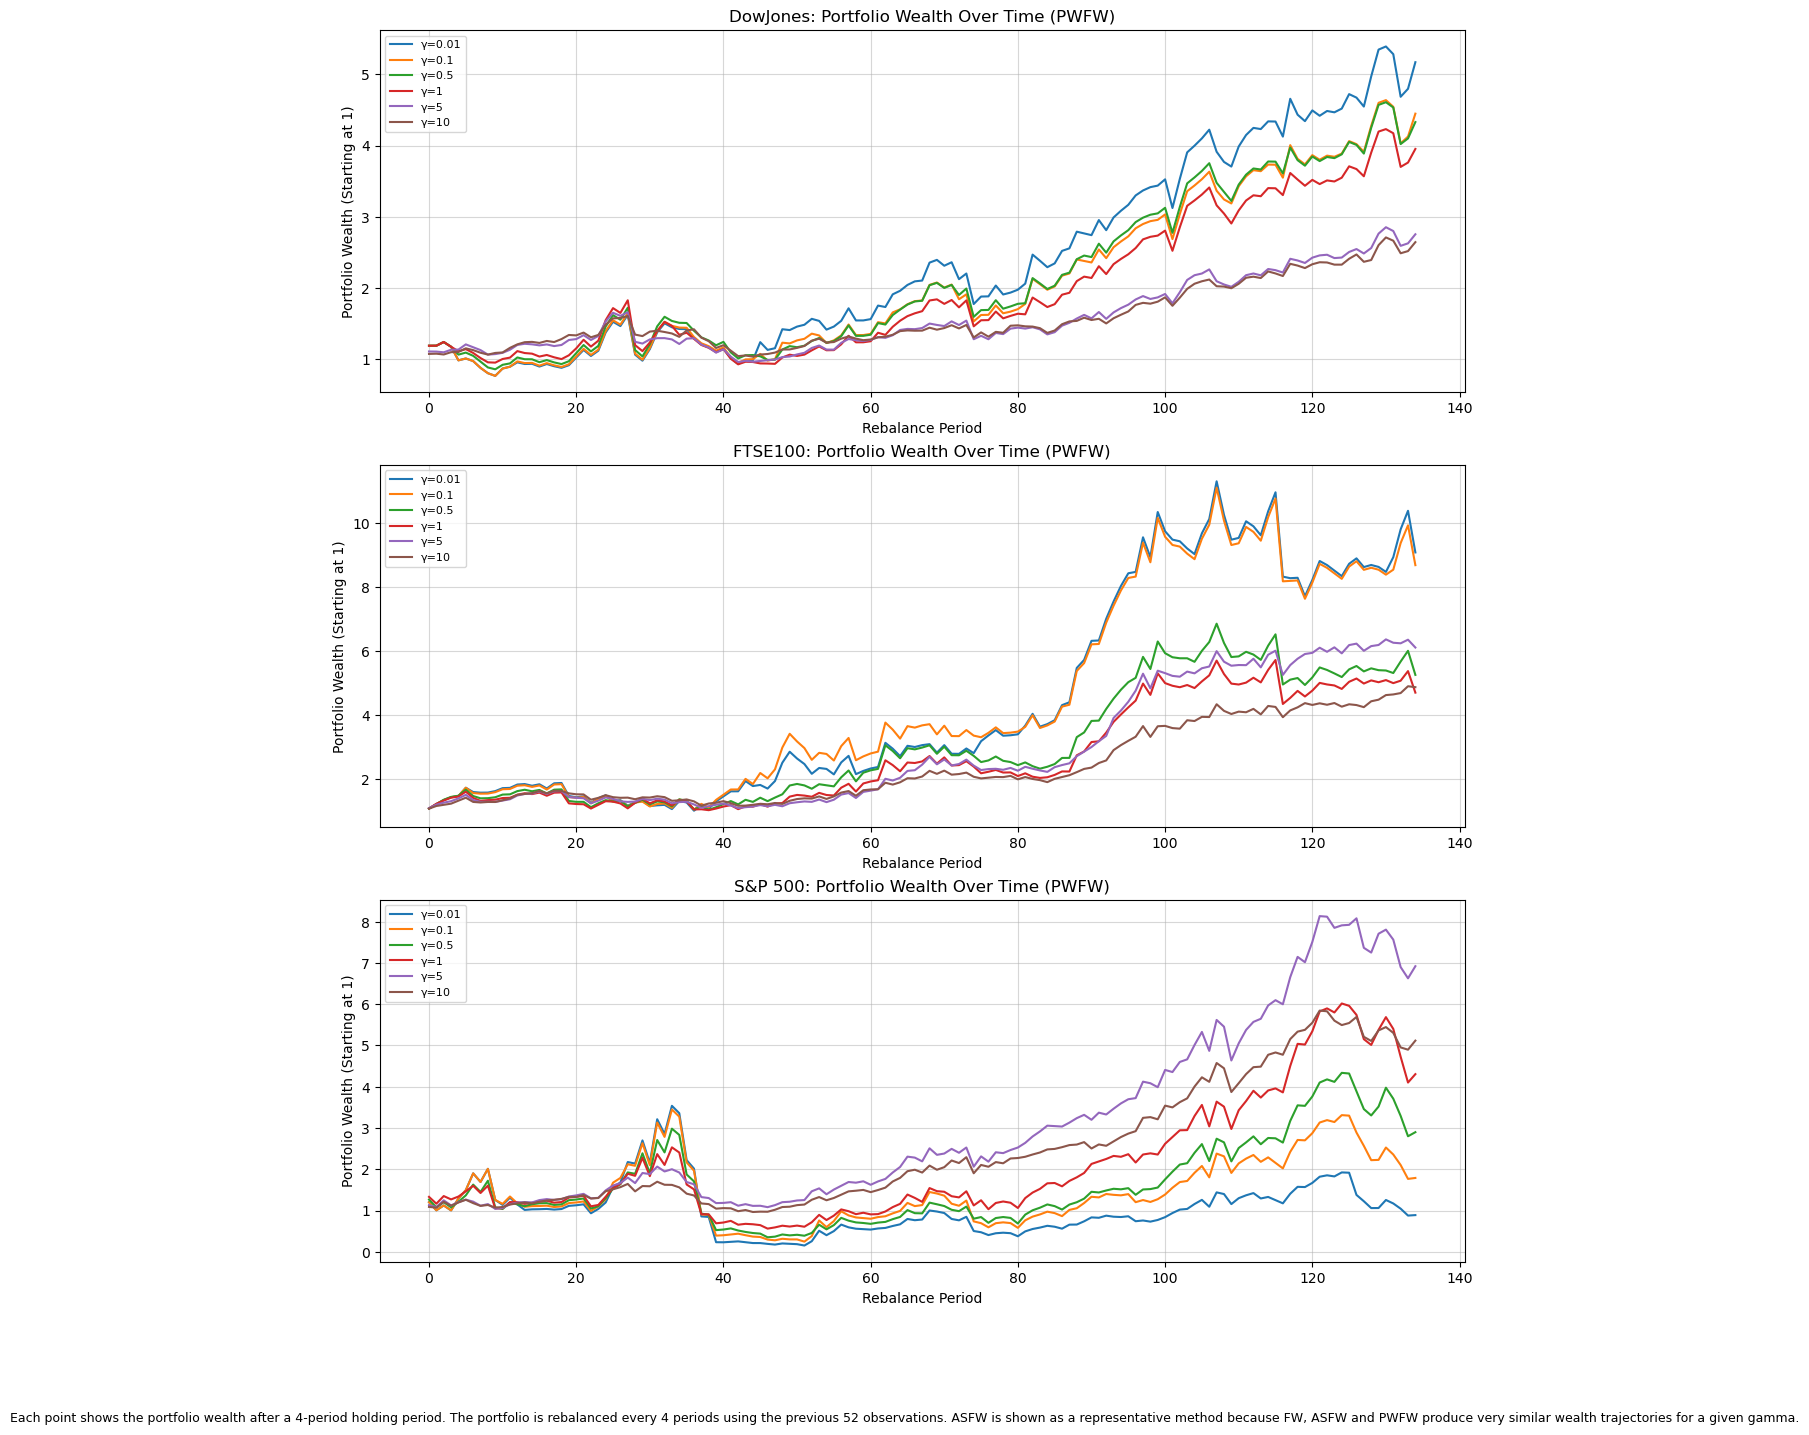

In [130]:
fig, axes = plt.subplots(3, 1, figsize=(14, 16))

plot_method = "pwfw"

for ax, (dataset_name, dataset_results) in zip(axes, all_results.items()):
    for gamma in gammas:
        df = dataset_results[gamma]
        method_df = df[
            (df["method"] == plot_method) &
            (df["f_horizon"] == 4)
        ].copy()

        method_df = method_df.sort_values("rebalance_period")

        ax.plot(
            method_df["rebalance_period"],
            method_df["budget"],
            label=f"γ={gamma}"
        )

    ax.set_title(f"{dataset_name}: Portfolio Wealth Over Time (PWFW)")
    ax.set_xlabel("Rebalance Period")
    ax.set_ylabel("Portfolio Wealth (Starting at 1)")
    ax.grid(True, alpha=0.5)
    ax.legend(fontsize=8, loc="upper left")

fig.text(
    0.5,
    0.01,
    "Each point shows the portfolio wealth after a 4-period holding period. "
    "The portfolio is rebalanced every 4 periods using the previous 52 observations. "
    "ASFW is shown as a representative method because FW, ASFW and PWFW produce "
    "very similar wealth trajectories for a given gamma.",
    ha="center",
    fontsize=9
)

plt.show()

In [131]:
selected_gammas = {
    'DowJones': 0.01,
    'FTSE100': 0.01,
    'S&P 500': 5.00
}

methods = ("fw", "asfw", "pwfw")

summary = []

for name, path in dataset_paths.items():

    data = pd.read_excel(
        path,
        sheet_name = 'Assets_Returns',
        header = None
    )

    data = data.tail(595).reset_index(drop=True)

    model = PortfolioOptimisation_rolling(data=data, 
        wind_size = 52,
        gamma = selected_gammas[name]
        )

    backtest = model.rolling_backtest(
        max_iter = 10000,
        tol = 1e-6,
        f_horizon = 4,
        methods = methods
    )

    for method in methods:

        df = backtest[backtest['method'] == method]

        summary.append({
            'Dataset': name,
            'Gamma': selected_gammas[name],
            'Algorithm': method,
            'Iterations': df['iter'].mean(),
            'Runtime (s)': df['time'].mean(),
            'Objective': df['obj'].mean(),
            'Final Gap': df['gap'].mean(),
            'Active Assets': df['active'].mean()
        })

summary_df = pd.DataFrame(summary)

print(summary_df.to_string(index=False))

 Dataset  Gamma Algorithm  Iterations  Runtime (s)  Objective     Final Gap  Active Assets
DowJones   0.01        fw    1.607407     0.000119  -0.010047 -1.021766e-21       1.007407
DowJones   0.01      asfw    1.607407     0.000288  -0.010047 -1.021766e-21       1.007407
DowJones   0.01      pwfw    1.607407     0.000153  -0.010047 -1.021766e-21       1.007407
 FTSE100   0.01        fw    2.066667     0.000266  -0.016417  5.053071e-09       1.022222
 FTSE100   0.01      asfw    2.037037     0.000334  -0.016417  2.498158e-09       1.022222
 FTSE100   0.01      pwfw    2.029630     0.000324  -0.016417  2.760821e-10       1.022222
 S&P 500   5.00        fw 8910.451852     0.920032  -0.011766  2.608750e-06       9.155556
 S&P 500   5.00      asfw   47.200000     0.005857  -0.011767  7.521743e-07       7.955556
 S&P 500   5.00      pwfw   35.059259     0.003803  -0.011767  7.279190e-07       7.962963
